In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
df = pd.read_csv("adult.csv")

# Data exploration
print("First Five Records\n")
print(df.head())

print("last Five Records\n")
print(df.tail())

print("\nDataset Information\n")
print(df.info())

print("\nDataset Description\n")
print(df.describe())

print("\nDataset Shape")
print(df.shape)

First Five Records

   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802          11th                7       Never-married   
1   38    Private   89814       HS-grad                9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm               12  Married-civ-spouse   
3   44    Private  160323  Some-college               10  Married-civ-spouse   
4   18          ?  103497  Some-college               10       Never-married   

          occupation relationship   race  gender  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      Husband  White    Male             0             0   
3  Machine-op-inspct      Husband  Black    Male          7688             0   
4                  ?    Own-child  White  Female             0             0   

   hours-per-week 

In [ ]:
df.columns = df.columns.str.strip()

df.replace("?", np.nan, inplace=True)

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

print("\nMissing Values")
print(df.isnull().sum())

df.dropna(inplace=True)

df.drop_duplicates(inplace=True)

df.reset_index(drop=True, inplace=True)

print("\nDataset Shape After Removing Missing Values:")
print(df.shape)


Missing Values
age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

Dataset Shape After Removing Missing Values:
(45175, 15)


In [ ]:
encoder = LabelEncoder()

for column in df.columns:
    if df[column].dtype == "object":
        df[column] = encoder.fit_transform(df[column])

print("\nColumn Names:")
print(df.columns)

X = df.drop("income", axis=1)
y = df["income"]


Column Names:
Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (36140, 14)
Testing Data Shape: (9035, 14)


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

In [ ]:
decision_tree_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    random_state=42
)
decision_tree_model.fit(X_train, y_train)

y_pred_dt = decision_tree_model.predict(X_test)

In [ ]:
def evaluate_model(y_test, y_pred, model_name):

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    print(model_name)
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

    return accuracy, precision, recall, f1

lr_results = evaluate_model(
    y_test,
    y_pred_lr,
    "LOGISTIC REGRESSION"
)

dt_results = evaluate_model(
    y_test,
    y_pred_dt,
    "DECISION TREE"
)

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        lr_results[0],
        dt_results[0]
    ],
    "Precision": [
        lr_results[1],
        dt_results[1]
    ],
    "Recall": [
        lr_results[2],
        dt_results[2]
    ],
    "F1 Score": [
        lr_results[3],
        dt_results[3]
    ]
})

print("MODEL COMPARISON")
print(comparison)

LOGISTIC REGRESSION
Accuracy : 0.8148312119535142
Precision: 0.8024155622955101
Recall   : 0.8148312119535142
F1 Score : 0.7995801900619552

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.88      6795
           1       0.70      0.45      0.54      2240

    accuracy                           0.81      9035
   macro avg       0.77      0.69      0.71      9035
weighted avg       0.80      0.81      0.80      9035

DECISION TREE
Accuracy : 0.8426120641947981
Precision: 0.8366133303082204
Recall   : 0.8426120641947981
F1 Score : 0.8296281113232561

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      6795
           1       0.79      0.50      0.61      2240

    accuracy                           0.84      9035
   macro avg       0.82      0.73      0.76      9035
weighted avg       0.84      0.84      0.83      9035

MODEL COMPARISON
       

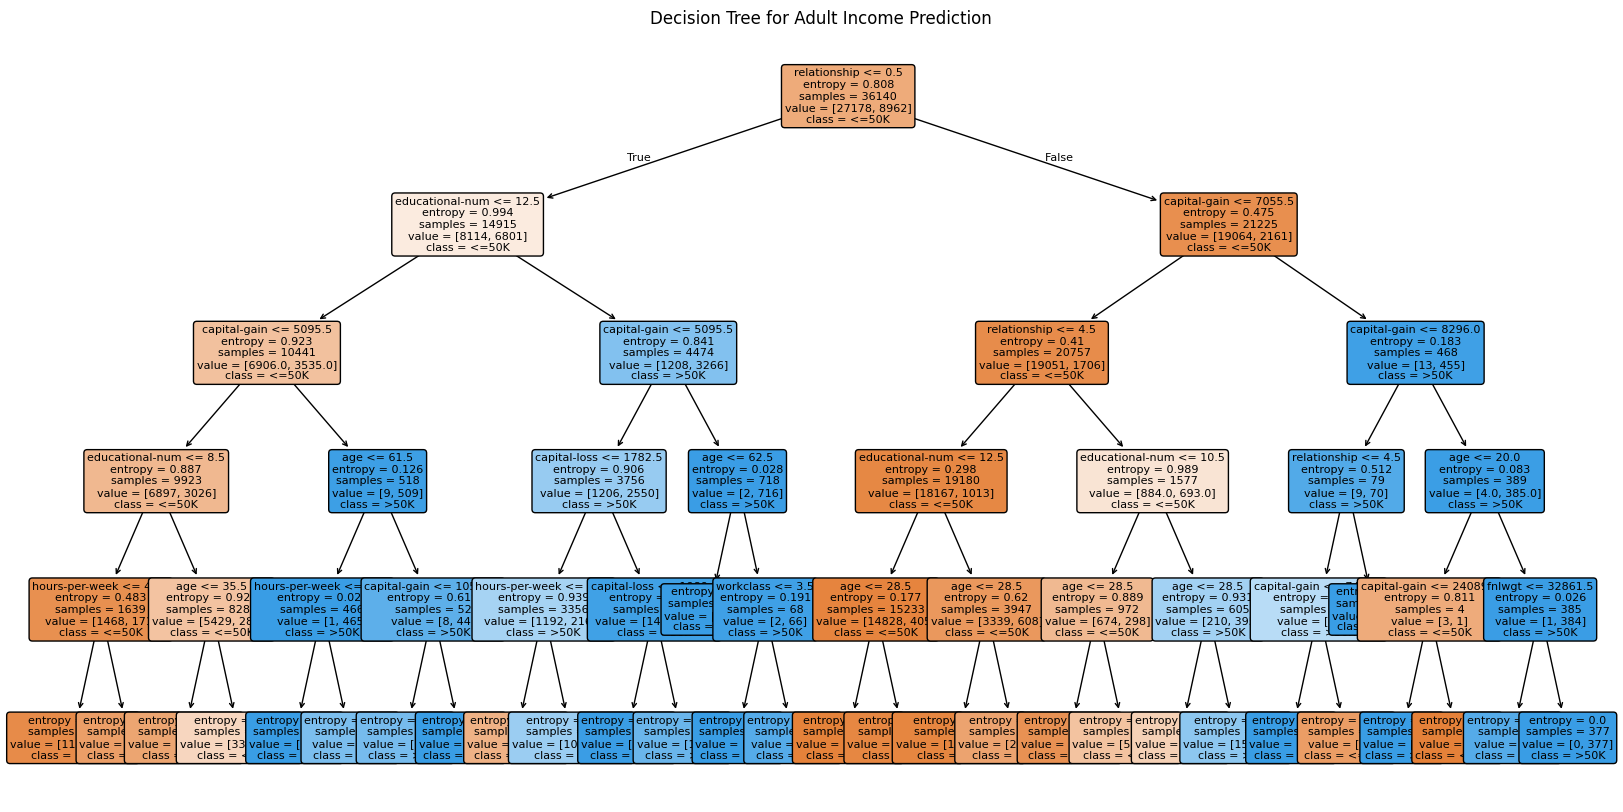

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    decision_tree_model,
    feature_names=X.columns,
    class_names=["<=50K", ">50K"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Adult Income Prediction")
plt.show()